In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, accuracy_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import os

os.chdir('/home/users/zwb3/research/falling-models')
from falling_trees.frl_rashomon_set_alg import OptFallingTree, print_tree
from falling_trees.binarize_dataset import binarize_dataset, cut
from experiments.utils import predict_proba_falling_tree, predict_falling_tree

In [2]:
SOFA_FEATURES = [
    'Total_Bilirubin_mg_per_dL', 'MAP', 'Creatinine_mg_per_dL', 'Dobutamine_any_dose', 'Dopamine_μg_kg_min',
    'Epinephrine_μg_kg_min', 'GCS', 'mech_vent_cpap', 'Norepinephrine_μg_kg_min', 'PaO2_FiO2', 'Platelets_10_3_per_ml',
    'Urine_output_mL'
]

In [3]:
sofa_data = pd.read_csv('data/MGH/processed_data/sofa_scores.csv')
full_data = pd.read_csv('data/MGH/processed_data/full_patient_df.csv')

In [4]:
full_data

,Admission,SexDSC,PatientRaceDSC,EthnicGroupDSC,Age,Hours_to_mortality,Days_to_mortality,Months_to_mortality,Years_to_mortality,Time_to_death,...,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2,FiO2,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL,died_in_ICU
0,0,Male,White,Not Hispanic,79,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,0.0,71.0,0.4,142.0,NaN,NaN,False
1,1,Male,White,Not Hispanic,63,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,10.5,125.0,0.4,208.0,155.0,1080.0,False
2,2,Female,White,Not Hispanic,75,8.0,0.0,9.0,3.0,1370 days 08:14:00,...,0.0,NaN,0.0,0.0,90.0,0.3,300.0,252.0,NaN,False
3,3,Female,White,Not Hispanic,78,8.0,20.0,0.0,0.0,20 days 08:53:00,...,0.0,12.0,0.0,0.0,NaN,NaN,NaN,207.0,1466.0,True
4,4,Male,White,Not Hispanic,21,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,37.5,NaN,NaN,NaN,358.0,1185.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,4995,Female,White,Not Hispanic,89,NaN,NaN,NaN,NaN,NaN,...,0.0,15.0,0.0,0.0,NaN,NaN,NaN,127.0,270.0,False
4996,4996,Female,Asian,Not Hispanic,89,18.0,5.0,1.0,0.0,36 days 18:22:00,...,0.0,15.0,0.0,0.0,NaN,NaN,NaN,114.0,755.0,False
4997,4997,Female,Asian,Not Hispanic,89,21.0,1.0,0.0,0.0,1 days 21:13:00,...,0.0,5.0,1.0,37.5,NaN,NaN,NaN,197.0,365.0,True
4998,4998,Male,White,Not Hispanic,72,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,NaN,NaN,NaN,159.0,975.0,False


In [5]:
full_X = full_data[SOFA_FEATURES]
full_y = full_data['died_in_ICU']

In [6]:
full_X

,Total_Bilirubin_mg_per_dL,MAP,Creatinine_mg_per_dL,Dobutamine_any_dose,Dopamine_μg_kg_min,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL
0,1.1,NaN,1.56,0.0,0.0,0.0,NaN,1.0,0.0,142.0,NaN,NaN
1,0.7,106.333333,1.19,0.0,0.0,0.0,NaN,1.0,10.5,208.0,155.0,1080.0
2,NaN,NaN,1.08,0.0,0.0,0.0,NaN,0.0,0.0,300.0,252.0,NaN
3,0.5,81.666667,1.62,0.0,0.0,0.0,12.0,0.0,0.0,NaN,207.0,1466.0
4,1.3,52.000000,0.86,1.0,0.0,0.0,NaN,0.0,37.5,NaN,358.0,1185.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,3.7,58.333333,3.04,0.0,0.0,0.0,15.0,0.0,0.0,NaN,127.0,270.0
4996,NaN,78.666667,1.31,0.0,0.0,0.0,15.0,0.0,0.0,NaN,114.0,755.0
4997,0.9,54.000000,2.52,0.0,0.0,0.0,5.0,1.0,37.5,NaN,197.0,365.0
4998,1.2,71.666667,1.34,0.0,27.8,0.0,NaN,0.0,0.0,NaN,159.0,975.0


In [7]:
X_train, X_test, y_train, y_test = train_test_split(full_X, full_y, test_size=0.2, random_state=42)

In [13]:
cat_model = CatBoostClassifier(verbose=False, auto_class_weights='Balanced')
cat_model.fit(X_train, y_train)
print(accuracy_score(y_test, cat_model.predict(X_test)))
print(balanced_accuracy_score(y_test, cat_model.predict(X_test)))

0.804
0.656503876687363


In [14]:
ebm_model = ExplainableBoostingClassifier(missing='low')
ebm_model.fit(X_train, y_train)
ebm_model.score(X_test, y_test)
print(accuracy_score(y_test, ebm_model.predict(X_test)))
print(balanced_accuracy_score(y_test, ebm_model.predict(X_test)))

2026-01-15 20:04:26,327 - INFO - EBM lib loading.
2026-01-15 20:04:26,328 - INFO - Finding library for Linux, x86_64, bitsize=64, debug=False
2026-01-15 20:04:26,330 - INFO - Loading EBM library /home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/interpret/utils/../root/bld/lib/libebm_linux_x64.so
/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(
2026-01-15 20:04:26,418 - INFO - Creating native dataset
2026-01-15 20:04:40,411 - INFO - Creating native dataset
2026-01-15 20:04:40,414 - INFO - Estimating with FAST
/home/users/zwb3/research/falling-models/.venv/lib/python3.

0.883
0.5156406058546731


In [15]:
linear_model = LinearRegression()
X_train_median = X_train.fillna(X_train.median())
X_test_median = X_test.fillna(X_train.median())
linear_model.fit(X_train_median, y_train)
print(accuracy_score(y_test, (linear_model.predict(X_test_median) > 0.5).astype(int)))
print(balanced_accuracy_score(y_test, (linear_model.predict(X_test_median) > 0.5).astype(int)))

0.889
0.5149816204862077


In [ ]:
df_fillna = X_train.fillna(-1000).copy()
df_fillna['label'] = y_train.values.astype(int)

n_pos = df_fillna['label'].sum()
# balance data
df_fillna = pd.concat([df_fillna[df_fillna['label'] == 1],
                       df_fillna[df_fillna['label'] == 0].sample(n_pos*2, random_state=42)],
                      axis=0).reset_index(drop=True)

df, thresholds, header, threshold_guess_time = binarize_dataset(df_fillna, 50)
X_train_fall = df.drop(columns=['label']).values
y_train_fall = df['label'].values
X_test_fall = cut(X_test.fillna(-1000), thresholds)[header].values


features = list(range(X_train_fall.shape[1]))
lam = 0.001
eps = 0.02
depth = 7  
enable_falling_constraint = True
use_heap = True  # Use heap for storing trees in Rashomon set
rule_list_mode_for_optimal = False
MAX_CACHE_SIZE = 100000  # Default value, can be adjusted
kwargs = {"branching_cost": 0.01, "min_support": 0.01}
# kwargs = {}
n = X_train_fall.shape[0]
row_idx = np.arange(n)

best_loss, best_tree, pmax, depth_of_pmax = OptFallingTree(X_train_fall,
                                                            y_train_fall,
                                                            row_idx,
                                                            depth,
                                                            lam,
                                                            features,
                                                            n=n,
                                                            enable_falling_constraint=enable_falling_constraint,
                                                            rule_list_mode=rule_list_mode_for_optimal,
                                                            **kwargs)

print_tree(best_tree)

NameError: name 'X_train_fillna' is not defined

In [ ]:
print("CatBoost Classification Report:")
print(classification_report(y_test, cat_model.predict(X_test)))
print("EBM Classification Report:")
print(classification_report(y_test, ebm_model.predict(X_test_fillna)))
print("Linear Regression Classification Report:")
print(classification_report(y_test, (linear_model.predict(X_test_median) > 0.5).astype(int)))
print("Falling Tree Classification Report:")
print(classification_report(y_test, predict_falling_tree(best_tree, X_test_fall)))

CatBoost Classification Report:
              precision    recall  f1-score   support

       False       0.90      0.98      0.94       891
        True       0.35      0.07      0.12       109

    accuracy                           0.88      1000
   macro avg       0.62      0.53      0.53      1000
weighted avg       0.84      0.88      0.85      1000

EBM Classification Report:
              precision    recall  f1-score   support

       False       0.89      0.98      0.94       891
        True       0.30      0.06      0.09       109

    accuracy                           0.88      1000
   macro avg       0.60      0.52      0.52      1000
weighted avg       0.83      0.88      0.85      1000

Linear Regression Classification Report:
              precision    recall  f1-score   support

       False       0.89      0.99      0.94       891
        True       0.40      0.04      0.07       109

    accuracy                           0.89      1000
   macro avg       0.65     

/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/interpret/utils/_clean_x.py:1332: UserWarning: Extra columns present in X that are not used by the model.
  warn("Extra columns present in X that are not used by the model.")


In [ ]:
from treefarms import TREEFARMS
X_train_tf = df.drop(columns=['label'])
y_train_tf = df['label']
tf_config = {
    'regularization': 0.005,
    'depth_budget': 5
}
tf = TREEFARMS(tf_config)
tf.fit(X_train_tf, y_train_tf)

X_test_tf = cut(X_test_fillna, thresholds)[header]
print(classification_report(y_test, tf[0].predict(X_test_tf)))

null
Finding Optimal Objective...
{
  "false": {
    "false": {
      "false": {
        "complexity": 0.004999999888241291,
        "loss": 0.04135802760720253,
        "name": "label",
        "prediction": 0.0
      },
      "feature": 22,
      "name": "Urine_output_mL<=1001.5",
      "reference": 1,
      "relation": "==",
      "true": {
        "false": {
          "complexity": 0.004999999888241291,
          "loss": 0.021604938432574272,
          "name": "label",
          "prediction": 0.0
        },
        "feature": 4,
        "name": "MAP<=70.16666793823242",
        "reference": 1,
        "relation": "==",
        "true": {
          "complexity": 0.004999999888241291,
          "loss": 0.03518518805503845,
          "name": "label",
          "prediction": 1.0
        },
        "type": "integral"
      },
      "type": "integral"
    },
    "feature": 10,
    "name": "Creatinine_mg_per_dL<=1.6150000095367432",
    "reference": 1,
    "relation": "==",
    "true": {
 

In [ ]:
tf.visualize()

Generating decision paths from 64 trees: 100%|██████████| 64/64 [00:00<00:00, 541.45it/s]


<iframe
 srcdoc="<!DOCTYPE html><html lang="en"><head><meta charset="UTF-8" /><meta name="viewport" content="width=device-width, initial-scale=1.0" /><title>TimberTrek</title><style>html{font-size:16px;-moz-osx-font-smoothing:grayscale;-webkit-font-smoothing:antialiased;text-rendering:optimizeLegibility;-webkit-text-size-adjust:100%;-moz-text-size-adjust:100%}html,body{position:relative;width:100%;height:100%}body{margin:0;padding:0;box-sizing:border-box;font-family:-apple-system,BlinkMacSystemFont,Segoe UI,Roboto,Oxygen-Sans,Ubuntu,Cantarell,Helvetica Neue,sans-serif;color:#4a4a4a;font-size:1em;font-weight:400;line-height:1.5}*,:after,:before{box-sizing:inherit}a{color:#0064c8;text-decoration:none}a:hover{text-decoration:underline}a:visited{color:#0050a0}label{display:block}input,button,select,textarea{font-family:inherit;font-size:inherit;-webkit-padding:.4em 0;padding:.4em;margin:0 0 .5em;box-sizing:border-box;border:1px solid #ccc;border-radius:2px}input:disabled{color:#ccc}button{color:#333;background-color:#f4f4f4;outline:none}button:disabled{color:#999}button:not(:disabled):active{background-color:#ddd}button:focus{border-color:#666}</style><script defer src='...'></script><script defer src='...'></script></head><body></body></html>"
 frameBorder="0"
 width="100%"
 height="650px"
 id="timbertrek-iframe-93556625">

In [ ]:
from pystreed import STreeDClassifier

X_train_streed = X_train.fillna(-1000)
y_train_streed = y_train
X_test_streed = X_test.fillna(-1000)


streed = STreeDClassifier(optimization_task="f1-score", max_num_nodes=10, max_depth=5)
streed = streed.fit(X_train_streed, y_train_streed)
print(classification_report(y_test, streed.predict(X_test_streed)))

              precision    recall  f1-score   support

       False       0.92      0.83      0.87       891
        True       0.24      0.44      0.31       109

    accuracy                           0.79      1000
   macro avg       0.58      0.63      0.59      1000
weighted avg       0.85      0.79      0.81      1000



In [ ]:
streed.print_tree()

Creatinine_mg_per_dL <= 1.92 not satisfied
|   MAP <= 76.333333 not satisfied
|   |   Total_Bilirubin_mg_per_dL <= 1.1 not satisfied
|   |   |   Label: 1
|   |   Total_Bilirubin_mg_per_dL <= 1.1 satisfied
|   |   |   Label: 0
|   MAP <= 76.333333 satisfied
|   |   Urine_output_mL <= 2257.5 not satisfied
|   |   |   Label: 0
|   |   Urine_output_mL <= 2257.5 satisfied
|   |   |   Label: 1
Creatinine_mg_per_dL <= 1.92 satisfied
|   mech_vent_cpap not satisfied
|   |   Label: 0
|   mech_vent_cpap satisfied
|   |   GCS <= 3.0 not satisfied
|   |   |   Urine_output_mL <= 1060.0 not satisfied
|   |   |   |   Label: 0
|   |   |   Urine_output_mL <= 1060.0 satisfied
|   |   |   |   Label: 1
|   |   GCS <= 3.0 satisfied
|   |   |   MAP <= 70.666667 not satisfied
|   |   |   |   GCS <= -1000.0 not satisfied
|   |   |   |   |   Label: 1
|   |   |   |   GCS <= -1000.0 satisfied
|   |   |   |   |   Label: 0
|   |   |   MAP <= 70.666667 satisfied
|   |   |   |   Norepinephrine_μg_kg_min <= 6.8 not s

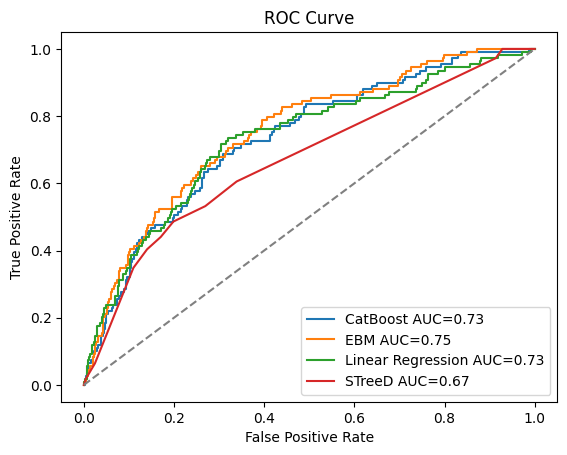

In [ ]:
roc_curve_cat = roc_curve(y_test, cat_model.predict_proba(X_test)[:, 1])
auc_cat = roc_auc_score(y_test, cat_model.predict_proba(X_test)[:, 1])
roc_curve_ebm = roc_curve(y_test, ebm_model.predict_proba(X_test)[:, 1])
auc_ebm = roc_auc_score(y_test, ebm_model.predict_proba(X_test)[:, 1])
roc_curve_linear = roc_curve(y_test, linear_model.predict(X_test_median))
auc_linear = roc_auc_score(y_test, linear_model.predict(X_test_median))
roc_curve_falling = roc_curve(y_test, predict_proba_falling_tree(best_tree, X_test_fall))
auc_falling = roc_auc_score(y_test, predict_proba_falling_tree(best_tree, X_test_fall))
roc_curve_streed = roc_curve(y_test, streed.predict_proba(X_test_streed)[:, 1])
auc_streed = roc_auc_score(y_test, streed.predict_proba(X_test_streed)[:, 1])

plt.plot(roc_curve_cat[0], roc_curve_cat[1], label=f'CatBoost AUC={auc_cat:.2f}')
plt.plot(roc_curve_ebm[0], roc_curve_ebm[1], label=f'EBM AUC={auc_ebm:.2f}')
plt.plot(roc_curve_linear[0], roc_curve_linear[1], label=f'Linear Regression AUC={auc_linear:.2f}')
#plt.plot(roc_curve_falling[0], roc_curve_falling[1], label=f'Falling Tree AUC={auc_falling:.2f}')
plt.plot(roc_curve_streed[0], roc_curve_streed[1], label=f'STreeD AUC={auc_streed:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()